# 1 · Wyżarzanie kwantowe: od problemu do QUBO / Isinga

**Koło Naukowe Qubit, PWr** · wyżarzanie kwantowe (D-Wave Ocean)

Komputer D-Wave **nie wykonuje obwodów z bramkami**. Rozwiązuje jeden typ zadania:
znajdź przypisanie zmiennych minimalizujące funkcję kwadratową (energię). Cała sztuka polega więc
na **zapisaniu swojego problemu w tej postaci**.

> 📚 Doczytaj: [D-Wave – Quantum annealing intro](https://docs.dwavequantum.com/en/latest/quantum_research/quantum_annealing_intro.html) ·
> [D-Wave – QUBO i Ising](https://docs.dwavequantum.com/en/latest/quantum_research/qubo_ising.html) · [D-Wave – kary (penalty)](https://docs.dwavequantum.com/en/latest/concepts/penalty.html) ·
> [Glover, Kochenberger, Du – *A Tutorial on Formulating and Using QUBO Models* (arXiv:1811.11538)](https://arxiv.org/abs/1811.11538)

In [2]:
import importlib.util
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)   # komunikaty o zmianach w kolejnych wersjach Ocean

import numpy as np
import matplotlib.pyplot as plt
import dimod
import dwave.graphs as dg
from dimod import ExactSolver
from dwave.samplers import SimulatedAnnealingSampler, TabuSampler
from dwave.system import EmbeddingComposite
from dwave.system.testing import MockDWaveSampler


## 1. Idea wyżarzania kwantowego (w 5 zdaniach)

1. Kubity to fizyczne „magnesiki” (spiny), które na końcu przyjmują wartość −1/+1 (albo 0/1).
2. Na starcie układ jest w łatwym do przygotowania stanie podstawowym (wszystkie spiny w superpozycji).
3. Powoli „wyłączamy” ten początkowy hamiltonian i „włączamy” hamiltonian **naszego problemu**.
4. Jeśli proces jest dość wolny (twierdzenie adiabatyczne), układ pozostaje blisko stanu o najniższej energii – czyli rozwiązania.
5. W praktyce szum i ograniczony czas powodują, że dostajemy **próbki** – wiele dobrych rozwiązań, nie zawsze optymalne.

Dlatego D-Wave zwraca **zbiór próbek** (`SampleSet`), a my wybieramy najlepszą.

## 2. QUBO i Ising

**QUBO** (zmienne $x_i \in \{0,1\}$):
$$E(x) = \sum_i a_i x_i + \sum_{i<j} b_{ij} x_i x_j + c$$

**Ising** (spiny $s_i \in \{-1,+1\}$):
$$E(s) = \sum_i h_i s_i + \sum_{i<j} J_{ij} s_i s_j + c$$

Przejście: $s = 2x - 1$. W `dimod` oba to ten sam obiekt `BinaryQuadraticModel` z innym `vartype`.

## 3. Przykład: „wybierz dokładnie jedną opcję” (ograniczenie one-hot)

Mamy trzy projekty z kosztami 3, 1, 2. Chcemy wybrać **dokładnie jeden**, najtańszy.
Wyżarzarka nie zna ograniczeń – dodajemy więc karę, która jest zerowa tylko dla poprawnych wyborów:

$$E(x) = \underbrace{3x_1 + 1x_2 + 2x_3}_{\text{koszt}} + \lambda\,\underbrace{(x_1+x_2+x_3-1)^2}_{\text{kara}}$$

Po rozwinięciu (bo $x_i^2 = x_i$) kara to: $-x_1-x_2-x_3 + 2x_1x_2 + 2x_1x_3 + 2x_2x_3 + 1$.

In [3]:
cost = {"A": 3, "B": 1, "C": 2}
lam = 5                                          # siła kary (mnożnik Lagrange'a) – musi przeważać nad kosztem

bqm = dimod.BinaryQuadraticModel("BINARY")
for v, c in cost.items():
    bqm.add_linear(v, c)
# kara lam * (sum x - 1)^2 – dimod ma do tego gotową funkcję:
bqm.update(dimod.generators.combinations(list(cost), 1, strength=lam))
print(bqm)

BinaryQuadraticModel({'A': -2.0, 'B': -4.0, 'C': -3.0}, {('B', 'A'): 10.0, ('C', 'A'): 10.0, ('C', 'B'): 10.0}, 5.0, 'BINARY')


In [4]:
# ExactSolver sprawdza wszystkie 2^n przypisań – tylko dla małych problemów, ale świetny do nauki
table = ExactSolver().sample(bqm)
print(table)

   A  B  C energy num_oc.
3  0  1  0    1.0       1
7  0  0  1    2.0       1
1  1  0  0    3.0       1
0  0  0  0    5.0       1
4  0  1  1    8.0       1
2  1  1  0    9.0       1
6  1  0  1   10.0       1
5  1  1  1   26.0       1
['BINARY', 8 rows, 8 samples, 3 variables]


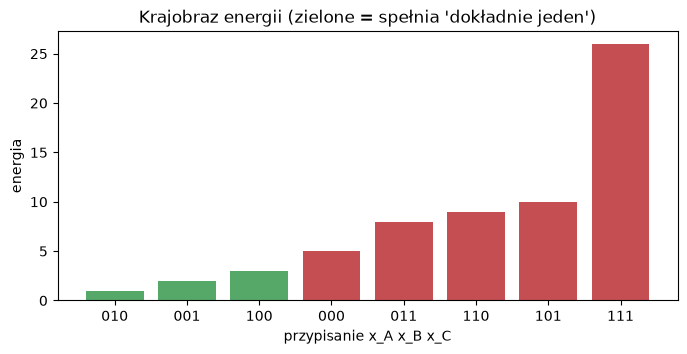

In [5]:
labels, energies, feasible = [], [], []
for s, e in table.data(["sample", "energy"]):
    labels.append("".join(str(s[v]) for v in cost))
    energies.append(e)
    feasible.append(sum(s.values()) == 1)

plt.figure(figsize=(8, 3.5))
plt.bar(labels, energies, color=["#55A868" if f else "#C44E52" for f in feasible])
plt.xlabel("przypisanie x_A x_B x_C"); plt.ylabel("energia")
plt.title("Krajobraz energii (zielone = spełnia 'dokładnie jeden')")
plt.show()

Najniższą energię ma `010` (wybieramy B, koszt 1). Wszystkie niedopuszczalne przypisania mają energię wyższą –
**o ile $\lambda$ jest wystarczająco duże**. Spróbuj $\lambda = 0.5$ i zobacz, co się stanie.

## 4. Ten sam model w postaci Isinga

In [6]:
h, J, offset = bqm.to_ising()
print("h =", {k: float(v) for k, v in h.items()})
print("J =", {k: float(v) for k, v in J.items()})
print("offset =", float(offset))

spin_bqm = bqm.change_vartype("SPIN", inplace=False)
best = ExactSolver().sample(spin_bqm).first
print("Najlepsze w spinach:", {k: int(v) for k, v in best.sample.items()}, "energia:", float(best.energy))

h = {'A': 4.0, 'B': 3.0, 'C': 3.5}
J = {('B', 'A'): 2.5, ('C', 'A'): 2.5, ('C', 'B'): 2.5}
offset = 8.0
Najlepsze w spinach: {'A': -1, 'B': 1, 'C': -1} energia: 1.0


## 5. Symulowane wyżarzanie – klasyczny odpowiednik

Dla większych problemów `ExactSolver` nie wystarczy ($2^{50}$ przypisań…). `SimulatedAnnealingSampler`
to **klasyczny** algorytm (z pakietu `dwave-samplers`), który ma ten sam interfejs co QPU (`sample(bqm, num_reads=...)`).
Dzięki temu kod piszesz raz, a sampler podmieniasz.

Przykład: łańcuch 30 spinów z losowymi oddziaływaniami (**szkło spinowe**) – typowy problem testowy dla wyżarzarek.

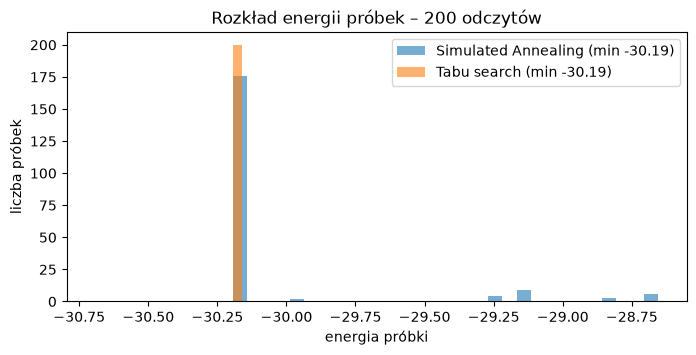

In [7]:
rng = np.random.default_rng(1)
N = 30
chain = dimod.BinaryQuadraticModel("SPIN")
for i in range(N - 1):
    chain.add_quadratic(i, i + 1, rng.choice([-1, 1]))
for i in range(N):
    chain.add_linear(i, rng.normal(0, 0.3))

samplers = {"Simulated Annealing": SimulatedAnnealingSampler(), "Tabu search": TabuSampler()}
plt.figure(figsize=(8, 3.5))
for name, sampler in samplers.items():
    ss = sampler.sample(chain, num_reads=200, seed=1)
    plt.hist(ss.record.energy, bins=30, alpha=.6, label=f"{name} (min {ss.first.energy:.2f})")
plt.xlabel("energia próbki"); plt.ylabel("liczba próbek"); plt.legend()
plt.title("Rozkład energii próbek – 200 odczytów")
plt.show()

In [8]:
ss = SimulatedAnnealingSampler().sample(chain, num_reads=200, seed=1)
print(ss.aggregate().truncate(5))      # 5 najlepszych unikalnych rozwiązań z liczbą wystąpień

   0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 ... 29     energy num_oc.
0 -1 -1 +1 -1 +1 +1 +1 -1 +1 +1 +1 +1 +1 +1 -1 -1 -1 ... -1 -30.193491     176
1 -1 -1 +1 -1 +1 +1 +1 -1 +1 +1 +1 -1 -1 -1 -1 -1 -1 ... -1 -29.963499       2
2 -1 -1 +1 -1 +1 +1 +1 -1 +1 +1 +1 -1 -1 -1 +1 +1 +1 ... -1 -29.229615       4
3 -1 -1 +1 -1 +1 +1 +1 -1 +1 +1 +1 -1 -1 -1 +1 +1 +1 ... +1  -29.14328       9
4 +1 +1 -1 +1 -1 -1 -1 +1 -1 -1 -1 +1 +1 +1 -1 -1 -1 ... -1  -28.85672       3
['SPIN', 5 rows, 194 samples, 30 variables]


## 6. Nasz problem na procesorze D-Wave

Kubity w procesorze D-Wave nie są połączone „każdy z każdym”. **Advantage2** ma układ połączeń **Zephyr**
(każdy kubit ma ok. 20 sąsiadów). Jeśli zmienna problemu potrzebuje więcej połączeń, niż ma jeden kubit,
reprezentuje ją **łańcuch** kilku kubitów, które zachowują się jak jeden. Przypisanie zmiennych do kubitów
to **embedding** – `EmbeddingComposite` znajduje je automatycznie.

`MockDWaveSampler` to lokalna atrapa procesora: ma prawdziwy układ kubitów i połączeń, ale wyniki liczy klasycznie.
Bierzemy **małą** siatkę Zephyr (160 kubitów), żeby dało się ją narysować, i uruchamiamy na niej
model wyboru projektu z sekcji 3 (`bqm`).


In [9]:
qpu = MockDWaveSampler(topology_type="zephyr", topology_shape=[2, 4])   # prawdziwy Advantage2: Zephyr [12, 4], ok. 4400 kubitów
print("Topologia:", qpu.properties["topology"], "| kubitów:", len(qpu.nodelist), "| połączeń:", len(qpu.edgelist))

sampler = EmbeddingComposite(qpu)        # znajduje embedding i tłumaczy wyniki z kubitów z powrotem na A, B, C
sampleset = sampler.sample(bqm, num_reads=100, return_embedding=True,
                           embedding_parameters={"random_seed": 1})
embedding = sampleset.info["embedding_context"]["embedding"]

print("Zmienna → fizyczne kubity:")
for v, chain in sorted(embedding.items()):
    print(f"  {v} → {list(chain)}")
print()
print(sampleset.aggregate().truncate(3))


Topologia: {'type': 'zephyr', 'shape': [2, 4]} | kubitów: 160 | połączeń: 1224
Zmienna → fizyczne kubity:
  A → [1]
  B → [3]
  C → [128]

   A  B  C energy num_oc. chain_. num_st.
0  0  1  0    1.0      65     0.0       1
1  0  0  1    2.0      22     0.0       1
2  1  0  0    3.0      13     0.0       0
['BINARY', 3 rows, 100 samples, 3 variables]


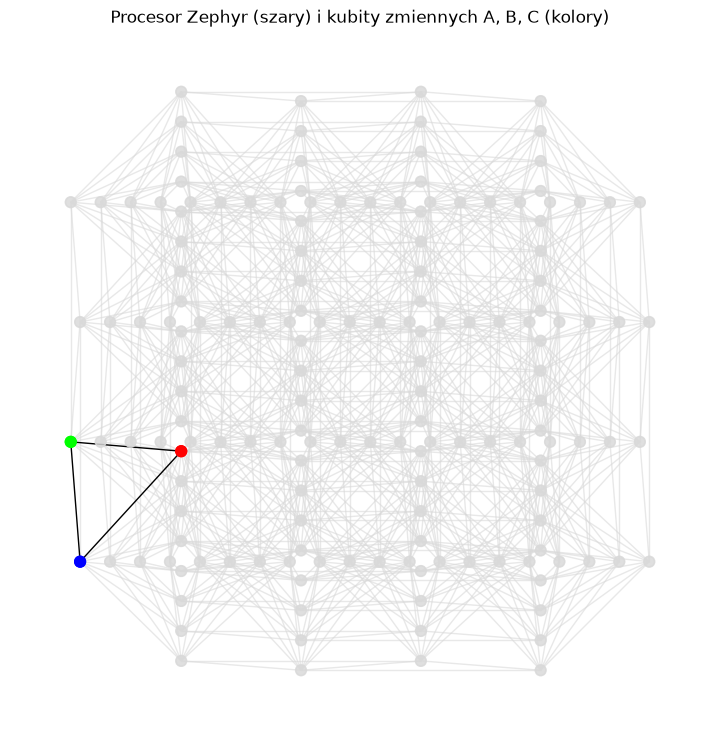

In [10]:
target = dg.zephyr_graph(2, 4, node_list=qpu.nodelist, edge_list=qpu.edgelist)
plt.figure(figsize=(7, 7))
dg.draw_zephyr_embedding(target, embedding, node_size=60, unused_color=(0.85, 0.85, 0.85, 0.6))
plt.title("Procesor Zephyr (szary) i kubity zmiennych A, B, C (kolory)")
plt.show()


### Problem Inspector

Problem Inspector pokazuje to samo w przeglądarce: problem, jego miejsce na procesorze i wyniki.
Instaluje się go osobno poleceniem `dwave install inspector` w terminalu z `nix develop`.

Inspector jest przygotowany dla wyników z prawdziwego procesora. Żeby pokazał wynik atrapy, dokładamy jej opis
solvera (funkcja `make_inspectable`). Na prawdziwym procesorze wystarczy `dwave.inspector.show(sampleset)`.


In [11]:
from dwave.cloud.solver import StructuredSolver

def make_inspectable(mock):
    """Dodaje do MockDWaveSampler atrybut `solver`, którego wymaga Problem Inspector."""
    mock.solver = StructuredSolver(client=None, data={
        "identity": {"name": "MockDWaveSampler"}, "status": "ONLINE",
        "description": "lokalna atrapa QPU", "avg_load": 0.0, "properties": dict(mock.properties)})
    return mock

make_inspectable(qpu)
sampleset = EmbeddingComposite(qpu).sample(bqm, num_reads=100, return_embedding=True,
                                           embedding_parameters={"random_seed": 1})

if importlib.util.find_spec("dwave._inspectorapp"):
    import dwave.inspector
    dwave.inspector.show(bqm, sampleset, qpu, block="never")     # otwiera Inspector w przeglądarce
else:
    print("Inspector nie jest zainstalowany – w terminalu z nix develop: dwave install inspector")
    print("Ten sam obraz pokazuje wykres powyżej.")


Inspector nie jest zainstalowany – w terminalu z nix develop: dwave install inspector
Ten sam obraz pokazuje wykres powyżej.
